## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

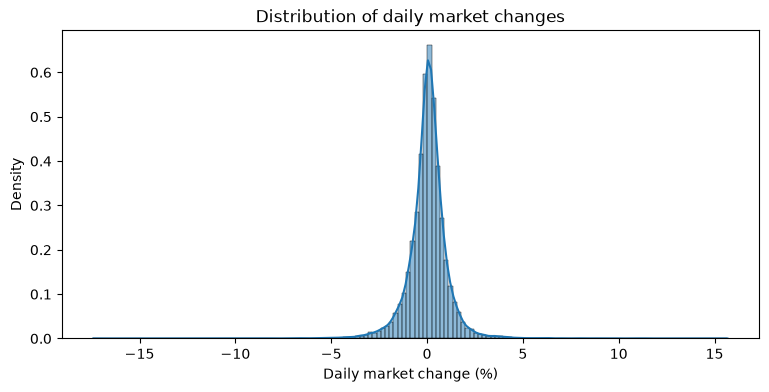

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

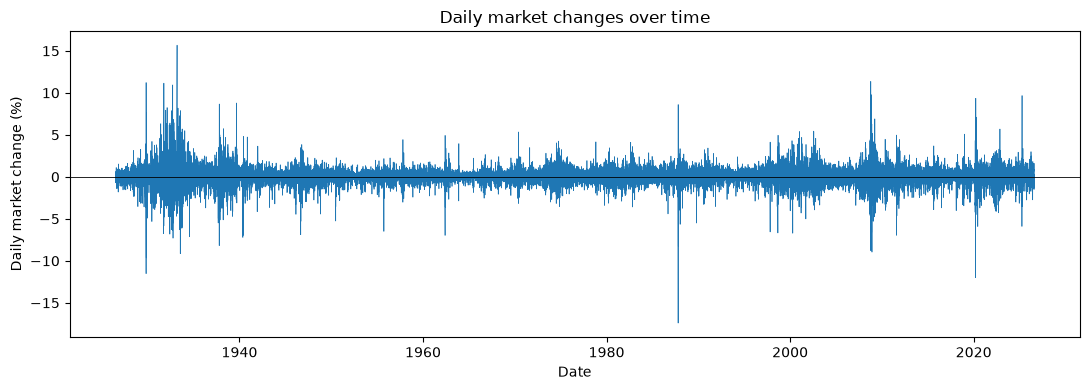

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

# Raw Counts:

In [23]:
df['direction'] = (df['market_return_pct'] > 0).map({True: 'Up', False: 'Down'})
df['tomorrow_direction'] = (df['market_return_pct'] > 0).shift(-1).map({True:'Up', False:'Down'})
pd.crosstab(df['direction'], df['tomorrow_direction'])

tomorrow_direction,Down,Up
direction,,
Down,5909,5999
Up,5999,8388


# Joint PMF with Margins:

In [ ]:
joint_tab = pd.crosstab(df['direction'], df['tomorrow_direction'], normalize=True, margins=True)
joint_tab

tomorrow_direction,Down,Up,All
direction,,,
Down,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


# Conditional PMF:

In [ ]:
conditional_tab = pd.crosstab(df['direction'], df['tomorrow_direction'], 
            normalize = 'index')
conditional_tab

tomorrow_direction,Down,Up
direction,,
Down,0.496221,0.503779
Up,0.416974,0.583026


- Up transitions are more common: looking at the marginal PMF we can see that up transitions account for 54.71% of total transitions (with down transitions accounting for 45.29% of them)
- More likely to transition to an up day from an up day (58.30%) than a down day (50.38%). These conditional probabilities are gathered from the conditional PMF above, below the "up" column (which indicates a transition to an up day)

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

# Bins and their counts:

In [35]:
df['market_return_bin'] = pd.cut(
    df['market_return_pct'],
    bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels=['Large Loss', 'Small Loss', 'Near Zero', 'Small Gain', 'Large Gain']
)
df['today_return_type'] = df['market_return_bin']
df['tomorrow_return_type'] = df['market_return_bin'].shift(-1)
df['today_return_type'].value_counts()

today_return_type
Small Gain    9785
Small Loss    7452
Near Zero     3441
Large Gain    2859
Large Loss    2759
Name: count, dtype: int64

- Number of days per bin are listed above
- Most common days are small gain days and small loss days, which are well above the other category days

# Joint PMF:

In [37]:
tab = pd.crosstab(df['today_return_type'], df['tomorrow_return_type'], normalize=True, margins=True)
tab

tomorrow_return_type,Large Loss,Small Loss,Near Zero,Small Gain,Large Gain,All
today_return_type,,,,,,
Large Loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small Loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near Zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small Gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large Gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<Axes: xlabel='tomorrow_return_type', ylabel='today_return_type'>

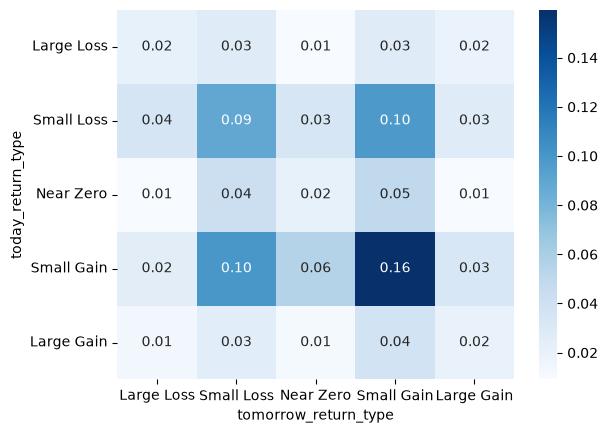

In [111]:
tab = pd.crosstab(df['today_return_type'], df['tomorrow_return_type'], normalize=True)
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

- Most likely transitions are small gain to small gain, small gain to small loss, small loss to small gain and small loss to small loss (darker squares in the heatmap)

# Conditional PMF:

In [109]:
conditional_tab = pd.crosstab(df['today_return_type'], df['tomorrow_return_type'], 
            normalize = 'index')
conditional_tab

tomorrow_return_type,Large Loss,Small Loss,Near Zero,Small Gain,Large Gain
today_return_type,,,,,
Large Loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small Loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near Zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small Gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large Gain,0.127317,0.234697,0.107030,0.347674,0.183281


<Axes: xlabel='tomorrow_return_type', ylabel='today_return_type'>

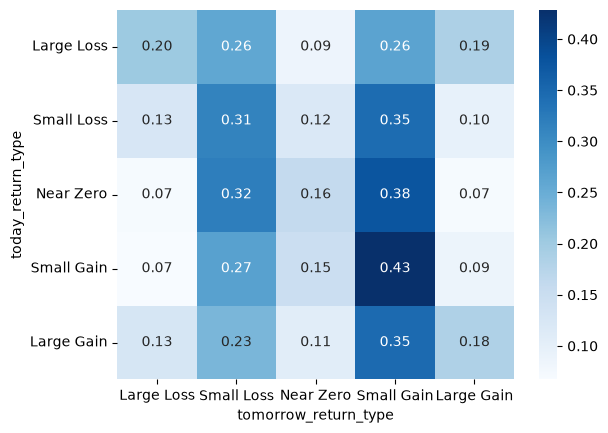

In [110]:
sns.heatmap(conditional_tab, annot=True, fmt='.2f', cmap='Blues')

- Large loss most likely next states: Small gain and small loss
- Small loss most likely next states: Small gain and small loss
- Near zero most likely next states: Small gain and small loss
- Small gain most likely next states: Small gain and small loss
- Large gain most likely next states: Small gain and small loss

- Subjectively, the probabilities of the next day's state are very similar (all are roughly not too far off of .2). This makes predicting the state tomorrow quite difficult as each state has a decent probability of occuring. Caveat is that generally small loss and small gain probabilities are relatively higher than large loss and large gain probabilities, but not very significantly.

# Conditional Returns:

In [48]:
df['tomorrow_return'] = df['market_return_pct'].shift(-1)
agg_comparison = df.groupby('today_return_type')['tomorrow_return'].describe()
agg_comparison

,count,mean,std,min,25%,50%,75%,max
today_return_type,,,,,,,,
Large Loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small Loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near Zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small Gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large Gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


- The conditional expectations for each state are listed above as the mean
- The min and max values generally are lower/higher at large returns (both gains and losses) but are smaller when returns are small or near zero.
- The large loss and large gain states have the highest standard deviation for tomorrow's returns
- Generally, volatility seems to be higher when there are already large positive/negative returns and volatility is less when returns are smaller in absolute value. Also, loss states seem to be relatively more volatile than gain states, as the std for loss return states are higher than their gain state counterparts

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [59]:
df['y_t'] = pd.qcut(df['market_return_pct'], q=21)
df['y_tp1'] = df['y_t'].shift(-1)

# Joint PMF

<Axes: xlabel='y_tp1', ylabel='y_t'>

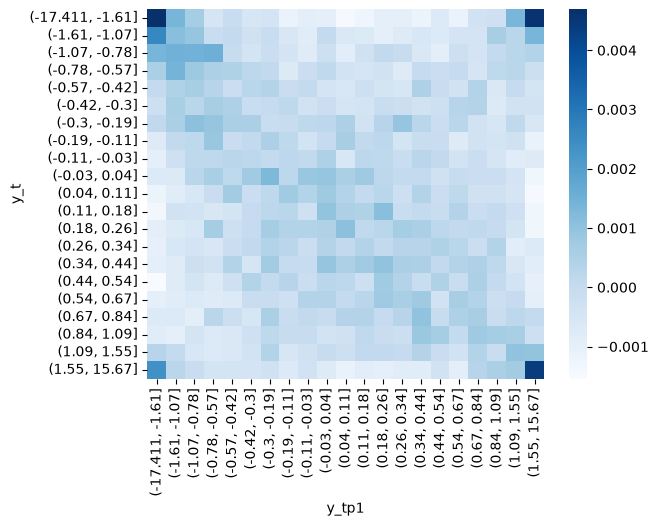

In [102]:
joint_tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
norm_joint = joint_tab - (1/21)**2
sns.heatmap(norm_joint, cmap='Blues')

- Pattern: The four corners of the heatmap are the darkest while there is a fainter density pattern from the top left corner to the bottom right. This indicates that the most often state transitions are from the highest bin to the highest and lowest bin and from the lowest bin to the lowest and highest bin. The faint diagonal density in the heatmap shows the other pattern of bins transitioning to the same bin or bins nearby.

# Conditional PMF

<Axes: xlabel='y_tp1', ylabel='y_t'>

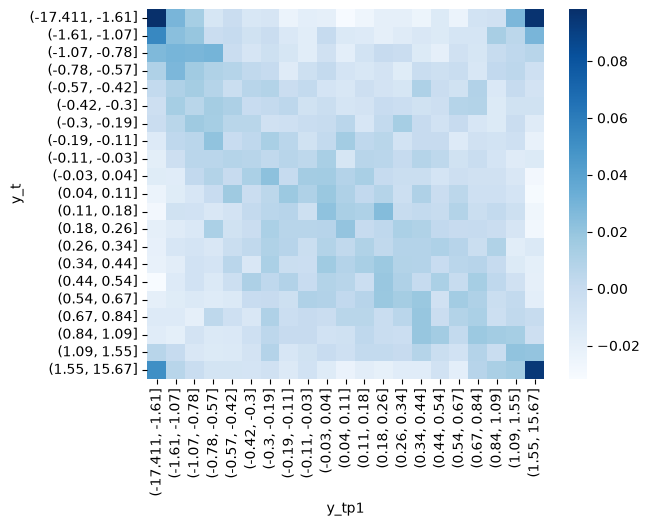

In [98]:
conditional_tab = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = 'index')
norm_conditional = conditional_tab - (1/21)
sns.heatmap(norm_conditional, cmap='Blues')

- Pattern: This heatmap looks almost identical to the previous joint PMF one where the corners are dark and there is a fainter diagonal line from the top left to the bottom right. This indicates that the most extreme bins are likely to end up in another extreme bin (both extremely positive or extremely negative). The middle bins have higher likelihoods of transitioning to a nearby bin.

# Min, Mean and Max Plot:

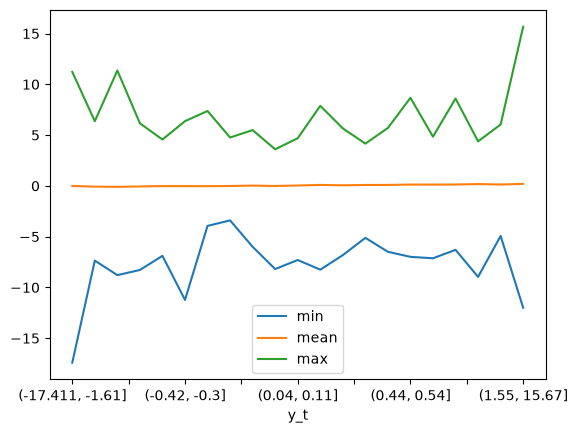

In [107]:
agg_comparison = df.groupby('y_t')['tomorrow_return'].describe().reset_index()
agg_comparison.plot(x="y_t", y=["min", "mean", "max"])
plt.show()

- Pattern: The mins and maxes for the next day returns are the lowest and highest respectively at both the lowest and highest bins. This again indicates that on a day with an extremely bad or good return we are likely to experience more volatility the next day and could end up with an extreme return in either direction. Days with milder returns tend to transition to mild return days as indicated by the min and max lines moving towards zero in the middle bins.
- The mean line is extremely consistent and never strays far from zero regardless of bin

# STD Plot:

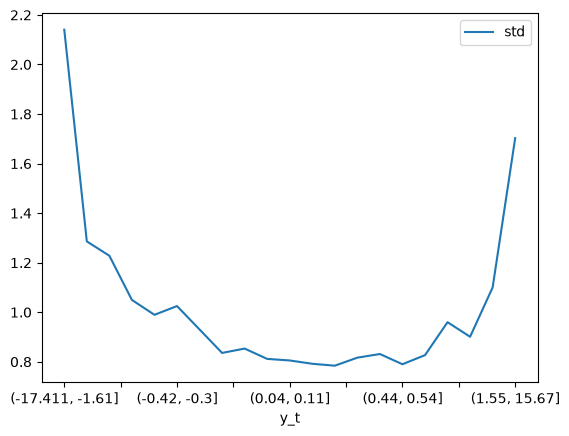

In [84]:
agg_comparison.plot(x="y_t", y='std')
plt.show()

- Pattern: This follows a similar to pattern to the min and max lines we saw above: there is much more volatility (high std) at the extreme bins (and especially in the extremely negative bins) while there is much more stability (low std) in the middle bins.

# How easy is it to predict the market?

- It is extremely hard to predict the market. We can see in the lab's evidence that the most consistent pattern is stable days usually transition to stable days and volatile days usually transition to volatile days. The issue is that the direction in this patttern is not consistent. Days with extreme returns are similarly likely to result in either an extreme gain or an extreme loss. The same can be said for mild returns. Because knowing the likely direction is the most important aspect for predicting the market and the data does not indicate a specific pattern in direction, predicting the market is very tough.